# 🏔️ The Optimizer Lab: Building and Racing Every Optimizer from Scratch

Welcome! If you have ever trained a machine learning model, you have seen loss numbers tick down on your screen. But what actually moves those numbers? How does a neural network adjust millions of weights to learn patterns?

The engine under the hood is an **optimization algorithm** (or **optimizer**).

In this interactive lab, we are going to:
1. Demystify the theory behind loss landscapes and gradients in plain English.
2. Build every major optimizer—**SGD**, **Momentum**, **Nesterov (NAG)**, **RMSProp**, **Adam**, and **AdamW**—completely from scratch using only NumPy.
3. Race them against each other on treacherous 2D mathematical test terrains.
4. Explore learning rates and decay schedules.
5. Benchmark them on a real computer vision model using PyTorch across multiple random seeds.
6. Uncover hidden failure modes where popular optimizers break down.

Let's begin our journey from zero to total confidence!

## 📚 The Living Glossary

Here is our master dictionary. Every time a new concept or term is introduced in this notebook, it is defined in plain language below.

| Term | Plain-English Definition |
| :--- | :--- |
| **Loss Function ($L$)** | A mathematical score showing how far our model's predictions are from reality (lower is better). |
| **Loss Landscape** | A multi-dimensional surface or topographic map of loss values across all possible parameter combinations. |
| **Parameter / Weight ($	heta$ or $w$)** | An adjustable dial inside the model that gets tuned to reduce the loss. |
| **Gradient ($
abla L$)** | A vector (arrow) pointing in the direction of steepest uphill climb on the loss surface. |
| **Learning Rate ($lpha$ or $\eta$)** | The step size multiplier; how far we move along the negative gradient direction in one step. |
| **Local Minimum** | A dip or valley floor where all immediate neighboring points have higher loss, but not necessarily the lowest on the entire map. |
| **Global Minimum** | The absolute lowest possible point on the entire loss landscape. |
| **Saddle Point** | A point where the slope is zero, but curves up in some directions and down in others (like a horse saddle). |
| **Sharp Minimum** | A narrow, steep pit. Moving even slightly off-center causes a massive spike in loss (generalizes poorly). |
| **Flat Minimum** | A broad, gentle basin. Small perturbations leave the loss low (generalizes well). |
| **Condition Number ($\kappa$)** | A ratio measuring how squashed or elongated a surface is: the ratio of maximum curvature to minimum curvature. |
| **Momentum** | A technique where the optimizer retains a running velocity of past gradients to roll smoothly through noise and ravines. |
| **Exponential Moving Average (EMA)** | A smoothed running average that gives more weight to recent values and decays older values exponentially. |
| **Second Moment ($v$ or $s$)** | The running average of squared gradients, tracking how volatile each individual parameter has been. |
| **Bias Correction** | A mathematical adjustment that prevents running averages from starting artificially close to zero at early steps. |
| **Weight Decay ($\lambda$)** | A regularization technique that gently shrinks weights toward zero to prevent overfitting. |
| **Decoupled Weight Decay** | Subtracting weight decay directly from weights rather than mixing it inside the adaptive gradient accumulator (the key innovation of AdamW). |

## 🔣 Mathematical Symbol Table

We will never show an equation without explaining every symbol in words. Refer to this table whenever you see math notation:

| Symbol | Name | Everyday Meaning | Typical Value |
| :--- | :--- | :--- | :--- |
| $	heta_t$ or $w_t$ | Theta / Weight at step $t$ | Current parameter value (our position on the mountain) | Real vector |
| $L(	heta)$ | Loss function | Current altitude / prediction penalty | Non-negative real scalar |
| $
abla L(	heta_t)$ or $g_t$ | Nabla $L$ / Gradient | Direction of steepest uphill climb at step $t$ | Vector of same shape as $	heta$ |
| $lpha$ or $\eta$ | Alpha / Learning Rate | Stride length multiplier | $10^{-4}$ to $0.1$ |
| $m_t$ or $v_t$ | First Moment / Velocity | Running average of past gradients (momentum buffer) | Vector of same shape as $	heta$ |
| $v_t$ or $s_t$ | Second Moment / Variance | Running average of past squared gradients | Vector of non-negative values |
| $eta$ or $eta_1$ | Beta 1 | Memory decay rate for past gradient directions | $0.9$ |
| $eta_2$ | Beta 2 | Memory decay rate for past gradient magnitudes | $0.999$ |
| $\epsilon$ | Epsilon | Microscopic safety buffer to prevent division by zero | $10^{-8}$ |
| $\lambda$ | Lambda | Weight decay penalty coefficient | $0.01$ |

---
## Step 1: Optimization Theory in Plain English

Before writing code, let's build an ironclad visual intuition of what optimization actually is. We will break this into five core ideas:
1. **The Loss Landscape**
2. **The Gradient**
3. **The Learning Rate**
4. **Terrain Hazards: Minima, Saddles, and Curvature**
5. **The Unifying Principle of Modern Optimizers**

### 1.1 The Loss Landscape

**1. The Idea in One Plain Sentence:**
A loss landscape is a mathematical elevation map that reveals how wrong our model's predictions are for every possible setting of its dials (parameters).

**2. A Real-Life Analogy:**
Imagine you are a hiker trapped in pitch-black night and thick fog in a mountain range. Your elevation represents your mistake: the higher up you are, the worse your predictions. Your goal is to descend to the lowest valley floor where elevation is zero.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Suppose our model has just one parameter $w$, and its loss is given by:
$$L(w) = (w - 3)^2$$
Let's test three different positions:
- If $w = 5$: Loss is $(5 - 3)^2 = 2^2 = 4$. (Moderate mistake)
- If $w = 1$: Loss is $(1 - 3)^2 = (-2)^2 = 4$. (Moderate mistake)
- If $w = 3$: Loss is $(3 - 3)^2 = 0^2 = 0$. (Perfect prediction! We are at the bottom of the bowl.)

**4. The Math with Every Symbol Explained in Words:**
$$L: \mathbb{R}^d 	o \mathbb{R}, \quad 	heta \mapsto L(	heta)$$
- $	heta$: A list of $d$ numbers representing our model parameters.
- $L(	heta)$: A single scalar number representing total prediction error on our training data.
- Our goal: Find $	heta^* = rg\min_{	heta} L(	heta)$ (the parameter values giving minimum loss).

**What we are about to do and why:**
In the code cell below, we will create and plot a 2D loss bowl $L(w_1, w_2) = w_1^2 + 2 w_2^2$ using contour lines so you can see what a 2-parameter loss landscape looks like from above.

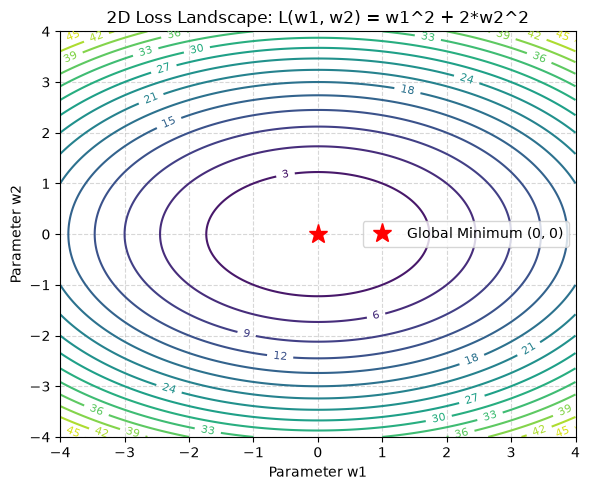

In [1]:
# Step 1.1 Code: Plotting a 2D Loss Landscape Contour Map
import numpy as np
import matplotlib.pyplot as plt

# Generate coordinate grid for parameters w1 and w2
w1 = np.linspace(-4, 4, 200)
w2 = np.linspace(-4, 4, 200)
W1, W2 = np.meshgrid(w1, w2)

# Compute loss surface: an elliptical bowl where w2 is twice as steep
Loss = W1**2 + 2 * W2**2

# Create contour plot
plt.figure(figsize=(6, 5))
contours = plt.contour(W1, W2, Loss, levels=15, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.plot(0, 0, 'r*', markersize=14, label='Global Minimum (0, 0)')
plt.title("2D Loss Landscape: L(w1, w2) = w1^2 + 2*w2^2")
plt.xlabel("Parameter w1")
plt.ylabel("Parameter w2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**What we just saw:**
We generated a top-down contour map. Each ring represents a line of constant loss elevation.

**How to Read this Plot:**
- **Axes:** The horizontal axis is parameter $w_1$; the vertical axis is parameter $w_2$.
- **Colors & Rings:** Purple/blue concentric rings represent low loss; yellow rings represent high loss. The numbers printed on the lines are loss values.
- **What a Good Result Looks Like:** Reaching the center marked with the red star $(0, 0)$ where loss is $0$.
- **What a Bad Result Looks like:** Wandering outward into the high-numbered rings where loss exceeds $30$.
- **What this Tells Us:** The contours are oval-shaped (ellipses) because the $w_2$ direction has a steeper multiplier ($2$) than $w_1$ ($1$). Steeper directions curve faster!

**Common Beginner Mistake:**
Confusing accuracy with loss. You want accuracy to be as high as possible ($100\%$), but loss measures error, so you want loss to be as low as possible ($0$).

**Quick Check Yourself Question:**
> **Question:** If your neural network has 10 million parameters, how many numbers does the loss function spit out?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Exactly **one** single scalar number! Regardless of whether a model has 2 parameters or 200 billion parameters, the loss function aggregates all predictions into one real number measuring overall error.
</details>

### 1.2 The Gradient: The Slope Under Our Boots

**1. The Idea in One Plain Sentence:**
The gradient is a vector (an arrow) pointing in the direction of steepest uphill climb, with a length proportional to how steep the slope is.

**2. A Real-Life Analogy:**
You are the hiker standing on a hillside in the fog. You feel the ground beneath your boots. The gradient points directly straight uphill. To walk downhill toward safety, you must take steps in the **exact opposite** direction of the gradient!

**3. Prerequisite Refresher: Derivatives in 5 Lines**
> A derivative tells us how fast an output changes when an input nudges forward.
> For $f(x) = x^2$, the derivative is $f'(x) = 2x$.
> At $x = 3$, $f'(3) = 6$.
> This means if we nudge $x$ by $+0.01$, $f(x)$ increases by roughly $6 \times 0.01 = +0.06$.
> A positive derivative means moving right increases loss; a negative derivative means moving right decreases loss.

**4. A Tiny Example with Real Numbers Worked by Hand:**
Take our bowl function:
$$L(w_1, w_2) = w_1^2 + 2 w_2^2$$
We compute the partial derivatives (derivative with respect to each parameter while treating the other as a constant):
$$\frac{\partial L}{\partial w_1} = 2 w_1, \qquad \frac{\partial L}{\partial w_2} = 4 w_2$$
Now suppose we are standing at point $(w_1 = 2, w_2 = 3)$:
$$\nabla L(2, 3) = \begin{bmatrix} 2(2) \\ 4(3) \end{bmatrix} = \begin{bmatrix} 4 \\ 12 \end{bmatrix}$$
- **Uphill vector (Gradient):** $[+4, +12]^T$ (points up and right).
- **Downhill direction (Negative Gradient):** $[-4, -12]^T$ (points down and left toward the bottom!).

**5. The Math with Every Symbol Explained in Words:**
$$\nabla L(\theta) = \left[ \frac{\partial L}{\partial \theta_1}, \frac{\partial L}{\partial \theta_2}, \dots, \frac{\partial L}{\partial \theta_d} \right]^T$$
- $\nabla$ (Nabla): The gradient operator symbol.
- $\frac{\partial L}{\partial \theta_i}$: How much loss shifts when dial $\theta_i$ is wiggled.
- The gradient vector has the exact same number of dimensions as the parameter vector $\theta$.

**What we are about to do and why:**
We will compute the gradient at $(2, 3)$ and plot both the uphill gradient vector and the downhill stepping vector on top of the loss contours.

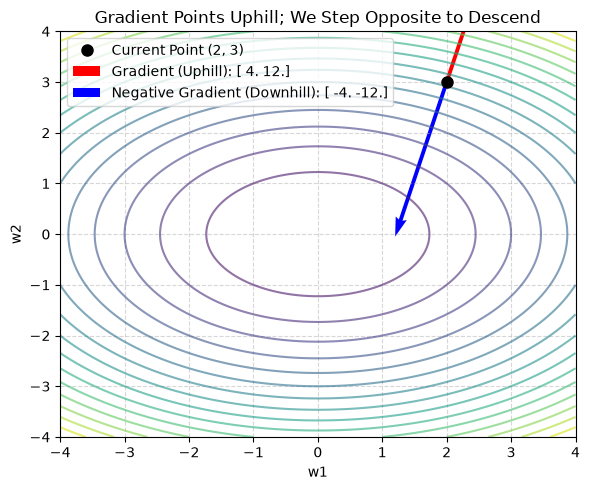

In [2]:
# Step 1.2 Code: Visualizing Gradient vs Negative Gradient Vector
# Current location on the landscape
curr_w = np.array([2.0, 3.0])
# Analytical gradient for L = w1^2 + 2*w2^2
grad = np.array([2.0 * curr_w[0], 4.0 * curr_w[1]])
neg_grad = -grad

plt.figure(figsize=(6, 5))
plt.contour(W1, W2, Loss, levels=15, cmap='viridis', alpha=0.6)
plt.plot(curr_w[0], curr_w[1], 'ko', markersize=8, label='Current Point (2, 3)')
# Plot gradient (uphill)
plt.quiver(curr_w[0], curr_w[1], grad[0], grad[1], color='red', 
           scale=40, label=f'Gradient (Uphill): {grad}')
# Plot negative gradient (downhill)
plt.quiver(curr_w[0], curr_w[1], neg_grad[0], neg_grad[1], color='blue', 
           scale=40, label=f'Negative Gradient (Downhill): {neg_grad}')
plt.title("Gradient Points Uphill; We Step Opposite to Descend")
plt.xlabel("w1"); plt.ylabel("w2"); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

**What we just saw:**
The red arrow points uphill into regions of higher loss. The blue arrow points downhill directly toward lower contours.

**How to Read this Plot:**
- **Axes:** Coordinates $w_1$ and $w_2$.
- **Arrows:** The red vector is $\nabla L$; the blue vector is $-\nabla L$.
- **What this Tells Us:** To minimize error, we must always walk in the direction of the blue arrow (the negative gradient). Notice that the blue arrow is tilted more strongly downward along $w_2$ because $w_2$ is steeper!

**Common Beginner Mistake:**
Believing the gradient vector points directly toward the global minimum. It does not! The gradient only knows about the **immediate local slope under your feet**. If the valley curves like a snake, the gradient points down the local bank, not around the bend.

**Quick Check Yourself Question:**
> **Question:** If the gradient at your current position is $\nabla L = [0, 0]^T$, what direction will a gradient descent step take?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** No step at all! The step size is $-\alpha \nabla L = -\alpha [0, 0]^T = [0, 0]^T$. When the slope is zero, standard gradient descent is completely stationary.
</details>

### 1.3 The Learning Rate: Our Stride Length

**1. The Idea in One Plain Sentence:**
The learning rate is a positive multiplier that controls how far we step along the downhill direction on each turn.

**2. A Real-Life Analogy:**
Think of the learning rate as your physical stride length.
- If your stride is microscopic ($1$ millimeter), you will safely descend, but it will take millions of years to reach the bottom.
- If your stride is gigantic ($50$ meters), you will leap clear across the valley and crash into the opposite cliff face.
- A well-tuned stride lets you jog down the mountain efficiently and safely.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let's minimize $L(w) = w^2$, starting at $w_0 = 4$.
The gradient is $\nabla L(w) = 2w$. At $w_0 = 4$, $\nabla L = 8$.
The update rule is:
$$w_{t+1} = w_t - \alpha \nabla L(w_t)$$
Let's compare three different learning rates:
- **Small ($\alpha = 0.1$):**
  $$w_1 = 4 - 0.1(8) = 4 - 0.8 = 3.2 \quad (\text{Loss drops from } 16 \to 10.24)$$
- **Just Right ($\alpha = 0.5$):**
  $$w_1 = 4 - 0.5(8) = 4 - 4.0 = 0.0 \quad (\text{Hits the exact minimum in one step!})$$
- **Overshooting ($\alpha = 1.0$):**
  $$w_1 = 4 - 1.0(8) = 4 - 8.0 = -4.0 \quad (\text{Bounces to the opposite side: } (-4)^2 = 16, \text{ stuck in loop})$$
- **Exploding / Diverging ($\alpha = 1.25$):**
  $$w_1 = 4 - 1.25(8) = 4 - 10.0 = -6.0 \quad (\text{Loss explodes from } 16 \to 36!)$$

**4. The Math with Every Symbol Explained in Words:**
$$\theta_{t+1} = \theta_t - \alpha g_t$$
- $\theta_{t+1}$: Our new position in parameter space at step $t+1$.
- $\theta_t$: Our current position at step $t$.
- $\alpha$: The learning rate (positive scalar, e.g. $0.01$).
- $g_t = \nabla L(\theta_t)$: The gradient evaluated at $\theta_t$.

**What we are about to do and why:**
We will simulate 10 steps of 1D gradient descent on $L(w) = w^2$ starting at $w = 4$ for three different learning rates ($lpha = 0.1, 0.9, 1.05$) to observe convergence, oscillation, and divergence side-by-side.

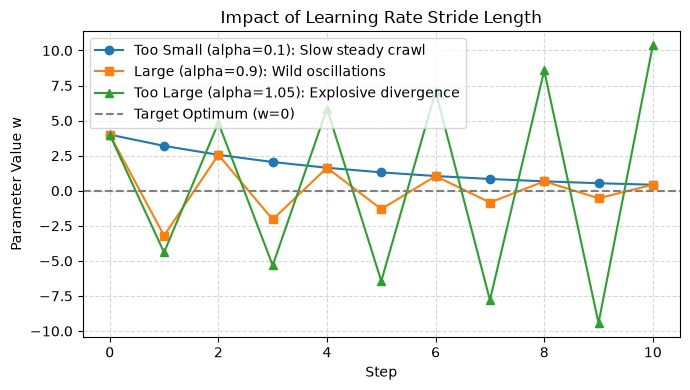

In [3]:
# Step 1.3 Code: Simulating Different Learning Rates on 1D Loss
def run_1d_descent(w_start, lr, steps=10):
    history = [w_start]
    w = w_start
    for _ in range(steps):
        grad = 2.0 * w       # Derivative of w^2 is 2w
        w = w - lr * grad     # Update rule
        history.append(w)
    return np.array(history)

steps = 10
hist_small = run_1d_descent(4.0, lr=0.1, steps=steps)
hist_oscillate = run_1d_descent(4.0, lr=0.9, steps=steps)
hist_diverge = run_1d_descent(4.0, lr=1.05, steps=steps)

plt.figure(figsize=(7, 4))
plt.plot(hist_small, 'o-', label='Too Small (alpha=0.1): Slow steady crawl')
plt.plot(hist_oscillate, 's-', label='Large (alpha=0.9): Wild oscillations')
plt.plot(hist_diverge, '^-', label='Too Large (alpha=1.05): Explosive divergence')
plt.axhline(0, color='gray', linestyle='--', label='Target Optimum (w=0)')
plt.xlabel("Step"); plt.ylabel("Parameter Value w"); plt.title("Impact of Learning Rate Stride Length")
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5); plt.tight_layout(); plt.show()

**What we just saw:**
- With $\alpha = 0.1$ (blue circles), the parameter smoothly inches toward $0$.
- With $\alpha = 0.9$ (orange squares), the parameter oscillates wildly across $0$ before settling.
- With $\alpha = 1.05$ (green triangles), the parameter bounces wider and wider, exploding out of control.

**How to Read this Plot:**
- **Axes:** Step number (x-axis) vs. Parameter value (y-axis).
- **Good Result:** A line that quickly and smoothly flattens at $w=0$.
- **Bad Result:** A line that either crawls too slowly or blows up toward $\pm \infty$.
- **What this Tells Us:** The learning rate is the single most sensitive dial in machine learning. Set it too small and training takes forever; set it slightly too big and the model explodes.

**Common Beginner Mistake:**
Thinking that when a neural network outputs `NaN` (Not a Number), it has a bug in its code. In $95\%$ of cases, `NaN` loss simply means your learning rate is too large and weights diverged to infinity!

**Quick Check Yourself Question:**
> **Question:** If your loss is dropping, but at an excruciatingly slow crawl after 100 epochs, should you increase or decrease the learning rate?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** You should carefully **increase** the learning rate (or use an adaptive optimizer with momentum) so each step covers more ground.
</details>

### 1.4 Terrain Hazards: Local Minima, Saddles, and Sharp vs. Flat Valleys

**1. The Idea in One Plain Sentence:**
Real loss landscapes are not smooth symmetrical bowls; they are riddled with deceptive plateaus, saddle passes, and narrow canyons that affect how well a model generalizes.

**2. A Real-Life Analogy:**
- **Global Minimum:** The deepest trench on Earth (Mariana Trench).
- **Local Minimum:** A small puddle trapped high on a ridge. If you step in any direction, you go uphill, but you are not at the bottom of the world.
- **Saddle Point:** A mountain pass between two peaks (looks like a horse saddle). Going north/south climbs uphill; going east/west descends downhill. Right at the pass center, the ground is dead flat ($
abla L = 0$).
- **Sharp vs. Flat Minima:**
  - *Sharp Minimum:* A tight, razor-sharp crevasse. If your test data is even slightly different from your training data, your position falls off the edge and loss skyrockets.
  - *Flat Minimum:* A wide, grassy valley floor. If test data causes a slight shift, you are still at the bottom and loss stays low!

**3. A Tiny Example with Real Numbers Worked by Hand:**
Consider the saddle function:
$$f(x, y) = x^2 - y^2$$
Gradient:
$$\nabla f(x, y) = [2x, -2y]^T$$
At $(0, 0)$:
$$\nabla f(0, 0) = [0, 0]^T$$
Even though the gradient is zero:
- If we move along $x$ (e.g. $x = 0.1, y = 0$): $f = (0.1)^2 = +0.01$ (uphill!).
- If we move along $y$ (e.g. $x = 0, y = 0.1$): $f = -(0.1)^2 = -0.01$ (downhill!).
This proves $(0, 0)$ is neither a minimum nor a maximum—it is a **saddle point**.

**What we are about to do and why:**
We will visualize both hazards in code: (1) a 3D saddle point surface where gradient vanishes, and (2) a comparison between a sharp minimum and a flat minimum under a slight data perturbation.

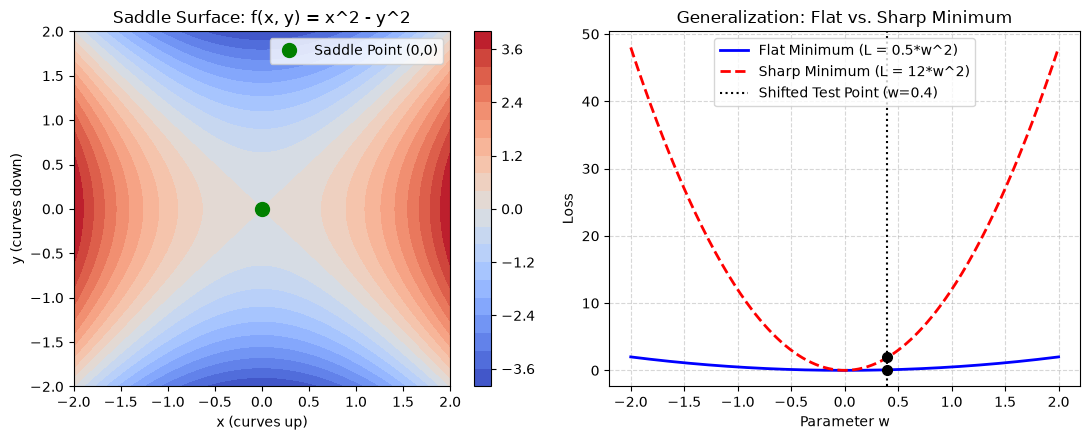

In [4]:
# Step 1.4 Code: Visualizing Saddle Points and Flat vs Sharp Minima
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)
Z_saddle = X**2 - Y**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Plot 1: Saddle Point Contour
cp = ax1.contourf(X, Y, Z_saddle, levels=20, cmap='coolwarm')
ax1.plot(0, 0, 'go', markersize=10, label='Saddle Point (0,0)')
ax1.set_title("Saddle Surface: f(x, y) = x^2 - y^2")
ax1.set_xlabel("x (curves up)"); ax1.set_ylabel("y (curves down)"); ax1.legend()
plt.colorbar(cp, ax=ax1)

# Plot 2: Sharp vs Flat Minimum Generalization
w = np.linspace(-2, 2, 200)
loss_flat = 0.5 * w**2
loss_sharp = 12.0 * w**2
shift = 0.4 # Small shift between train and test distribution
ax2.plot(w, loss_flat, 'b-', linewidth=2, label='Flat Minimum (L = 0.5*w^2)')
ax2.plot(w, loss_sharp, 'r--', linewidth=2, label='Sharp Minimum (L = 12*w^2)')
ax2.plot([shift, shift], [0.5*shift**2, 12*shift**2], 'ko', markersize=7)
ax2.axvline(shift, color='k', linestyle=':', label=f'Shifted Test Point (w={shift})')
ax2.set_title("Generalization: Flat vs. Sharp Minimum")
ax2.set_xlabel("Parameter w"); ax2.set_ylabel("Loss"); ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(); plt.show()

**What we just saw:**
- In the left plot, $(0,0)$ has zero slope, but escaping along $y$ leads to much lower values. Plain gradient descent can get stuck here or crawl at a snail's pace!
- In the right plot, when test data nudges the parameter by $+0.4$, the flat minimum (blue) barely registers any error ($0.08$), while the sharp minimum (red) explodes to error $1.92$.

**How to Read this Plot:**
- **Left Plot:** Saddle surface contours. Blue represents valleys; red represents ridges. The green point is dead-center.
- **Right Plot:** 1D cross-section showing loss as parameters deviate from optimal.
- **What this Tells Us:** Optimization is not just about finding *any* zero-loss point. We specifically want optimizers that find **broad, flat valleys** because flat valleys generalize well to real-world test data!

**Common Beginner Mistake:**
Believing that in deep networks, getting trapped in bad local minima is the main reason models fail. In modern high-dimensional neural nets, true local minima are usually close in value to the global minimum. The real culprits that stall training are **saddle points** and **steep ravines**!

**Quick Check Yourself Question:**
> **Question:** Why do modern optimizers like Momentum and Adam escape saddle points much faster than plain SGD?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Because Momentum preserves past velocity! Even if the gradient hits zero right at the saddle point, the momentum buffer carries velocity from previous steps, rolling the optimizer right past the flat plateau.
</details>

### 1.5 The Unifying Idea of Modern Optimizers

Now, here is the master insight that ties this entire lab together. Every modern optimizer—from simple SGD to cutting-edge AdamW—is just a variation of one single master formula:

$$\text{Parameter Update} = -\alpha \cdot \Big[ \text{Per-Parameter Adaptive Scaling} \Big] \cdot \Big[ \text{Memory of Past Gradients} \Big]$$

Let's see how each famous optimizer builds upon this foundation:

1. **SGD (Stochastic Gradient Descent):**
   - Memory: None (only uses current gradient $g_t$).
   - Adaptive Scaling: None (uses the exact same learning rate $lpha$ for all parameters).
2. **SGD + Momentum:**
   - Memory: **YES!** Uses an Exponential Moving Average (EMA) of past gradients (like a heavy rolling bowling ball).
   - Adaptive Scaling: None.
3. **Nesterov Accelerated Gradient (NAG):**
   - Memory: **YES!** Looks ahead in the direction of momentum before measuring the gradient.
   - Adaptive Scaling: None.
4. **RMSProp:**
   - Memory: None on direction.
   - Adaptive Scaling: **YES!** Divides each coordinate by the square root of recent gradient magnitudes. Steep parameters take smaller steps; shallow parameters take bigger steps!
5. **Adam (Adaptive Moment Estimation):**
   - Memory: **YES!** Tracks first moment (momentum).
   - Adaptive Scaling: **YES!** Tracks second moment (RMSProp scaling).
   - Plus **Bias Correction** to fix startup lag.
6. **AdamW:**
   - Adam with **Decoupled Weight Decay**: shrinks weights directly without distorting the adaptive gradient history.

Here is the lineage tree in a simple diagram:

```
           Plain SGD (Only current gradient gt)
                      │
        ┌─────────────┴─────────────┐
        ▼                           ▼
Add Momentum Memory           Add Per-Parameter Scaling
 (SGD + Momentum, NAG)                (RMSProp)
        │                           │
        └─────────────┬─────────────┘
                      ▼
               Combine Both!
                  (Adam)
                      │
                      ▼
           Decouple Weight Decay
                 (AdamW)
```

### 📝 Step 1 Recap

**Recap in 3 Bullets:**
1. A **loss landscape** is an elevation map of errors; the **gradient** tells us which way is steepest uphill, and we step in the opposite direction scaled by the **learning rate**.
2. Loss surfaces are filled with hazards like **saddle points** (flat passes) and **ill-conditioned ravines** where standard gradient descent struggles.
3. Every advanced optimizer combines two tricks: **momentum memory** (to power through flats and smooth oscillations) and **per-parameter adaptive scaling** (to equalize fast and slow coordinates).

> 💡 **If you remember only one thing:**
> Optimization is simply deciding **which direction to face** (using current slope and past momentum) and **how big of a stride to take for each individual parameter** (using adaptive scale and learning rate).